<a href="https://colab.research.google.com/github/ashah778/Data-201-Project1/blob/main/Arnav_Shah_DATA_201_Project_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 201 Project 1: BRCA Classification

The Big Question
How can we build and evaluate classification models to make predictions about a
real-world outcome?



In my project, I am going to use numerical measurements from the Breast Cancer dataset to predict whether a breast mass is benign (B) or malignant (M).

I will compare the four classification models and figure out which one makes the most accurate predictions.



Introduction:


The dataset I chose is the Wisconsin Diagnostic Breast Cancer dataset which I got from the UC Irvine Machine Learning Repository. It contains 569 rows with 30 numerical features based on measurements of cell nuclei from breast mass samples.

I chose this dataset because I wanted to understand how machine learning can use medical data to predict whether a tumor is benign or malignant.

In this project, I am going to explore the dataset by examining the variables, by doing Logistic Regression, LDA, QDA, and KNN. My goal is to evaluate each model to see how well it classifies the breast cancer cases and how it determins the model that predicts the best.

## Part 1 — Understanding the problem


1. What is the goal of the classification problem?

I am using the Breast Cancer dataset to predict whether a breast mass is benign or malignant. Each row is an observation and the columns help determine the difference between the diagnosis. The response variable is y which is either benign (B) or malignant (M).

2. What are the response variable and predictors?

The response variable is y that identifies whether a mass is benign (B) or malignant (M). I will use the numerical columns as predictors and remove the ID columns since it identifies the observation rather than describing the mass.

3. How many observations belong to each class?

The dataset contains 357 benign observations (which is 62.74%) and 212 malignant observations ( which is 37.26%), for a total of 569 observations.


4. What is a false positive, and what is a false negative?

A false positive occurs when a benign mass is predicted to be malignant. This causes unecessary stress which could allow testing to happen.

A false negative occurs when a malignant mass is predicted to be benign. This is very worrysome due to there being a chance of delay for medical evaluation.

5. Which type of error is more concerning, and why?

The type of error I am most worried about is false negatives. A false negative happens when the model predicts a cancerous mass as benign which has likelihood of delaying medical evaluation.


False positives are important because they happen when the model predicts a benign mass as cancerous which leads to additional testing.

### Part 2 — Exploring and Preparing the Data

Question 1. Investigate your features and predictors.

For Slide 2 also

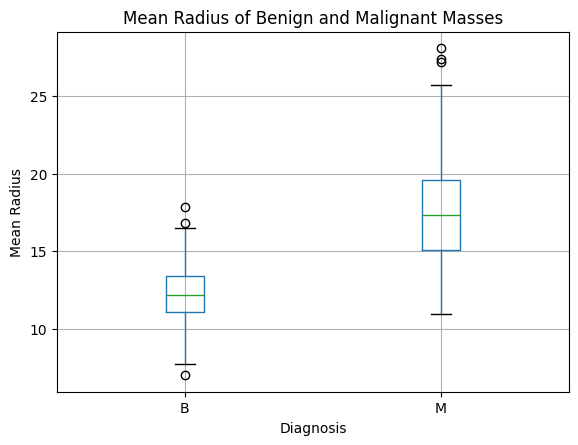

In [17]:
# I am comparing mean radius for benign and malignant masses.
brca.boxplot(column="x.radius_mean", by="y")

# I am labeling my graph.
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.title("Mean Radius of Benign and Malignant Masses")
plt.suptitle("")

# I am displaying the boxplot.
plt.show()

Analysis:

Malignant masses had a higher median radius at about 17 than benign masses at about 12, which shows the radius can help distinguish diagnoses and predict whether a mass is benign or malignant.

In [1]:
# Source: Week 1,2,3 Lab

# I am importing the tools I need to access Google Drive,
# organize my data into a table, and explore the dataset.
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# I am saving the location of my BRCA dataset in Google Drive.
# This will help Python to find the file.
path = "/content/drive/MyDrive/Data_201 /Datasets/brca.csv"
brca = pd.read_csv(path)

# I am displaying the first five rows to analyze how the observations and columns are organized.
# Each row represents one observation which is present in the dataset
brca.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


In [5]:
# Here I am printing the number of rows and columns
# The first number tells me how many rows there are,
# and the second number tells me how many columns there are.
print("Dataset shape:", brca.shape)


# Here I am displaying the column names that are present in my dataset
print("Column names:")
print(brca.columns)

# I am displaying summary statistics for the numerical columns.
# These statistics are values such as
# mean, standard  deviation, minimum, maximum, and the 25%, 50% ,and 75% quartiles.
brca.describe()


Dataset shape: (569, 32)
Column names:
Index(['Unnamed: 0', 'x.radius_mean', 'x.texture_mean', 'x.perimeter_mean',
       'x.area_mean', 'x.smoothness_mean', 'x.compactness_mean',
       'x.concavity_mean', 'x.concave_pts_mean', 'x.symmetry_mean',
       'x.fractal_dim_mean', 'x.radius_se', 'x.texture_se', 'x.perimeter_se',
       'x.area_se', 'x.smoothness_se', 'x.compactness_se', 'x.concavity_se',
       'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se',
       'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst',
       'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst',
       'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst',
       'x.fractal_dim_worst', 'y'],
      dtype='object')


,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,569.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [6]:

# Here I am counting how many observations belong to each diagnosis.
# For the outputs below the label B represents benign and M represents malignant
print("Diagnosis counts:")
print(brca["y"].value_counts())

# Here I am calculating the percent for the diagnosis
# normalize = TRUE will give the percentage
# I did *100 since it converts to percent
print("Diagnosis percentages:")
print(brca["y"].value_counts(normalize=True) * 100)

Diagnosis counts:
y
B    357
M    212
Name: count, dtype: int64
Diagnosis percentages:
y
B    62.741652
M    37.258348
Name: proportion, dtype: float64


Analysis:

For this part I analyzed the first five rows. I also analyzed dimensions of the dataset as well as the summary statistics to understand what this data is talking about. The numerical columns are measuring the breast mass. Meanwhile the y shows if the diagnosis is benign (B) or malignant (M).

The dataset has 569 with 357 benign cases (at about 62.74%) and 212 malignant cases (at about 37.26%). I will use the numerical measurements to make predictions while excluding the ID column since it labels each sample.

### Part 2 — Exploring and Preparing the Data

Question 2:

Determine whether your dataset contains missing values. If it does, explain how you handled them.

## Checking for Missing Values and Cleaning the Dataset

In [7]:

# Source: The textbook chapters
# Source: Lab 1,2
# Source: College dataset hw

# I am checking every column to determine whether any observations have missing values..
print("Missing values before cleaning:")
print(brca.isnull().sum())

# I am recording the original number of rows before cleaning.
rows_before = brca.shape[0]

# I am removing the first column because it contains the ID.
# The ID identifies each observation but does not describe a
# measurement of the breast mass that I want to use for prediction.
brca = brca.drop(brca.columns[0], axis=1)

# I am removing rows that contain missing values.
# If no missing values are present, no rows will be removed by this step.
brca = brca.dropna()

Missing values before cleaning:
Unnamed: 0             0
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64


In [8]:
# I am checking the dimensions since I am cleaning the dataset
print("Cleaned dataset shape:", brca.shape)

# I am viewing the first five rows again to analyze how the observations and columns are organized.
display(brca.head())

# Using this I am checking to see if there are any missing values
print("Missing values after cleaning:")
print(brca.isnull().sum())

Cleaned dataset shape: (569, 31)


,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,x.fractal_dim_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,0.05766,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,0.06811,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,0.06905,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,0.05863,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,0.06503,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


Missing values after cleaning:
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64


Analysis:

I checked each column for missing values using isnull().sum(). All of the columns had no missing values, which is why I had to remove no rows.

I noted the original number of rows as well as I removed the ID column due to it not classifying the breast masses. I also used dropna() to remove rows which had missing values.

At last, I checked the dataset to finalize the cleaning portion of the data.

Question 3:

Determine whether any categorical predictors need to be encoded before modeling

## Seperate the predictors as well as the response

In [44]:
# textbook chapters
# Source: College Dataset Homework
# Source: Lab 3
# Source: Lab 4/5
# Source: Lab 6

# I created X to store the predictor variables.
# Predictors are the measurements that the models will use to identify patterns to try to predict a diagnosis
# I am removing the y column since I am trying to predict that
X = brca.drop(columns=["y"])

# I created the y to store the diagnosis for the observation.
# This is the diagnosis which the model will predict.
y = brca["y"]

# I am displaying the names of the predictors so I can see the columns that I will use
# to try to help me build the model.
print("Predictor columns:")
print(X.columns)

# I am counting the number of observations that belong to each diagnosis.`
print("Class counts:")
print(y.value_counts())

Predictor columns:
Index(['x.radius_mean', 'x.texture_mean', 'x.perimeter_mean', 'x.area_mean',
       'x.smoothness_mean', 'x.compactness_mean', 'x.concavity_mean',
       'x.concave_pts_mean', 'x.symmetry_mean', 'x.fractal_dim_mean',
       'x.radius_se', 'x.texture_se', 'x.perimeter_se', 'x.area_se',
       'x.smoothness_se', 'x.compactness_se', 'x.concavity_se',
       'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se',
       'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst',
       'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst',
       'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst',
       'x.fractal_dim_worst'],
      dtype='object')
Class counts:
y
B    357
M    212
Name: count, dtype: int64


Analysis:

I separated the measurements from the diagnosis. The reason why I did that was because the predictors in this were all numerical which is why encoding is not needed. Encoding means to change the category names into numbers for the model to use. However, my predictors are already numerical which is why I do not need to encode for this.

The dataset had 357 benign cases B and 212 malignant cases M. That is why I decided to do B and M labels since the models can implement directly.

Question 4:

Divide the data, then use k-fold CV on training data.

## Splitting the data to try to do Cross Validation

In [43]:
# Source: Week 3 Lab .
# Source: Week 4/5 Lab


# I am importing the tools that I need to divide my dataset into the training and testing
# sets as well as setting up cross-validation.

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# I am dividing my predictors and response into training and testing.
# The training set will be implemented for my classification models.
# The test set will be separate for model evaluation

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# I am doing the five-fold stratified cross-validation.
# The training data will be divided into five parts.
# Four folds are used for training and one fold will be implemented for validation.

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# Here I am checking the number of observations and predictors in the training set
# I am checking the number of observations and predictors in the test set

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

# I am counting the benign and malignant diagnoses in the training set.
# This helps me figure out if the classses are present in the data
print("Training diagnosis counts:")
print(y_train.value_counts())

# I am counting the benign and malignant diagnoses for the test set.
# This helps me figure out if the classses are present in the data
print("Testing diagnosis counts:")
print(y_test.value_counts())

Training set: (426, 30)
Testing set: (143, 30)
Training diagnosis counts:
y
B    267
M    159
Name: count, dtype: int64
Testing diagnosis counts:
y
B    90
M    53
Name: count, dtype: int64


Analysis:

In this I am spliting the dataset into a training set ( which is 75%) and a test set ( which is 25%). The training set has 426 observations, and the test set has 143. I used stratify=y to have the percent for benign and malignant around the same.

I also used five-fold cross-validation on the training data. So what I did was training the model five times. I tried to kept the test data separate for evaluating the model.

I also used Cross Validation which is a technique used to test a model from the training data to see if there are good results. Cross-validation helps data scientists see how the model does by doing something called splitting the training data.

Question 5:

Determine whether predictors should be standardized for any of the classifiers you will use.


I will standardize the predictors for Logistic Regression and KNN from StandardScaler(). This helps change the measurements for a mean of 0 and a standard deviation of 1. This is benefical for KNN since the scale would be good.

make_pipeline() is important I can try to explain why. First of all it helps prevent data leakage by calculating the scaling values from the training data. The reason why it does not have a good impact is cause there is normally a high chance of inaccurate results to happen.

My goal is to make my models as accurate as possible to see how well they can predict whether a breast mass is benign or malignant. This could help researchers understand the potential use of classification models in medical research.

Question 1. Logistic Regression

In [11]:
# Source: Week 3 Lab
# Source: Week 4/5 Lab
# Source: Week 6 Lab


from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline



# Here I am scaling the predictors and setting up Logistic Regression.
# Here I am allowing uo to max 1000 iterations to try to find a solution from this model
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)



In [12]:
# I am using five-fold cross-validation on my training data.
logistic_cv = cross_val_score(
    logreg, X_train, y_train, cv=kfold
)

# I am printing the accuracy for each fold and the average.
print("Logistic Regression CV scores:", logistic_cv)
print("Mean CV accuracy:", logistic_cv.mean())

# I am fitting Logistic Regression on all my training data.
logreg.fit(X_train, y_train)

# I am predicting diagnoses for my test data.
logistic_pred = logreg.predict(X_test)

# I am calculating the predicted probabilities.
logistic_prob = logreg.predict_proba(X_test)


Logistic Regression CV scores: [1.         0.98823529 0.97647059 0.97647059 1.        ]
Mean CV accuracy: 0.9882352941176471


In [13]:
# I am calculating the predicted probability of each diagnosis.
logistic_prob = logreg.predict_proba(X_test)

# I am checking the order of the diagnosis classes.
print("Class order:", logreg.classes_)

# I am comparing actual and predicted diagnoses.
logistic_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": logistic_pred
})

# I am displaying the results.
logistic_results



Class order: ['B' 'M']


,Actual,Predicted
196,B,B
200,B,B
467,M,M
324,B,B
2,B,B
...,...,...
203,B,B
254,B,B
153,B,B
297,B,B


Analysis:

I trained Logistic Regression using my training data and evaluated it with five-fold cross-validation. My mean cross validation was 98.82%.

For example, observation 196 was correctly predicted as benign. I will use these predictions and probabilities to evaluate the models later in the project.

Question 2. Linear Discriminant Analysis (LDA)

In [14]:
# Source: Week 3 Lab
# Source: Week 4/5 Lab
# Source: Week 6 Lab


from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# I am creating an LDA model.
lda = LinearDiscriminantAnalysis()

# I am evaluating LDA with five-fold cross-validation on my training data.
lda_cv = cross_val_score(lda,
                         X_train,
                         y_train,
                         cv=kfold)


# I am printing the accuracy from each fold and the average accuracy.
print("LDA CV scores:", lda_cv)
print("Mean CV accuracy:", lda_cv.mean())

# I am fitting the LDA on all my training data.
lda.fit(X_train, y_train)

# I am predicting the diagnoses for the test data
lda_pred = lda.predict(X_test)


LDA CV scores: [0.97674419 0.96470588 0.95294118 0.96470588 1.        ]
Mean CV accuracy: 0.9718194254445965


Analysis:

I trained LDA using the same training data that I used for Logistic Regression. My mean cross validation for LDA was 97.18%. It is a little bit smaller compared to Logistic which was 98.82%.

Question 3. Quadratic Discriminant Analysis (QDA)

In [15]:

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# I am creating a QDA model.
qda = QuadraticDiscriminantAnalysis()

# I am evaluating QDA with five-fold cross-validation on my training data.
qda_cv = cross_val_score(qda, X_train, y_train, cv=kfold)

# I am printing the accuracy from each fold and the average accuracy.
print("QDA CV scores:", qda_cv)
print("Mean CV accuracy:", qda_cv.mean())

# I am fitting the QDA on all my training data.
qda.fit(X_train, y_train)

# I am predicting the diagnoses for the test data
qda_pred = qda.predict(X_test)


QDA CV scores: [0.97674419 0.92941176 0.96470588 0.95294118 0.98823529]
Mean CV accuracy: 0.962407660738714


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

Analysis:

I used the same training data and predictors. I used five-fold cross-validation to evaluate QDA and the accuracy was about 96.24%. Then I trained the QDA model to predict the diagnosis.

Question 4: K-Nearest Neighbors (KNN)

In [16]:

# Source: Lab 4/5
# Source: Lab 6

from sklearn.neighbors import KNeighborsClassifier

# I am choosing the K values I want to compare through cross-validation.
k_values = range(1, 21)

# I am creating a list to store the cross-validation accuracy for each K.
knn_scores = []

# I am testing different values of K to determine the best performance.
for k in k_values:

    # I am scaling the predictors and creating the KNN model with the current K.
    knn_model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    # I am calculating the accuracy for each of the five cross-validation folds.
    scores = cross_val_score(knn_model,
                             X_train,
                             y_train,
                             cv= 5)

    # I am saving the average accuracy across the five folds.
    knn_scores.append(scores.mean())


K values: range(1, 21)
Mean CV accuracies: [np.float64(0.9623803009575923), np.float64(0.9553488372093023), np.float64(0.9600547195622436), np.float64(0.9624076607387142), np.float64(0.9577017783857729), np.float64(0.9647606019151848), np.float64(0.9623803009575923), np.float64(0.9647606019151848), np.float64(0.9624076607387142), np.float64(0.9647606019151848), np.float64(0.9647606019151848), np.float64(0.9530232558139536), np.float64(0.9577291381668948), np.float64(0.9577291381668948), np.float64(0.9577291381668948), np.float64(0.9577291381668948), np.float64(0.9577291381668948), np.float64(0.9553761969904242), np.float64(0.9483173734610123), np.float64(0.9506703146374831)]


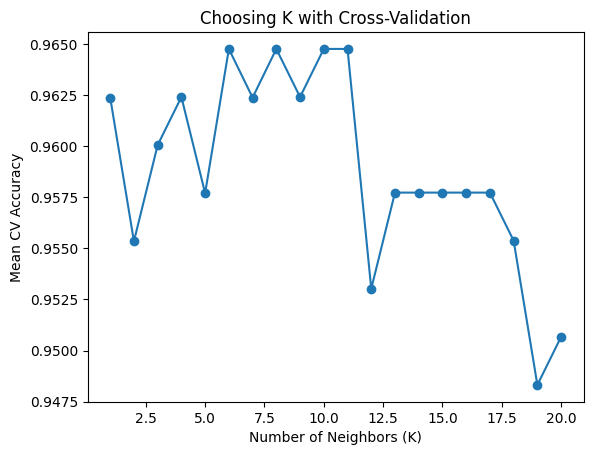

In [ ]:

# I am displaying the K values and their mean cross-validation accuracies.
print("K values:", k_values)
print("Mean CV accuracies:", knn_scores)

# I am plotting the results to compare the different K values.
plt.plot(k_values, knn_scores, marker="o")

plt.xlabel("Number of Neighbors (K)")

plt.ylabel("Mean CV Accuracy")

plt.title("Choosing K with Cross-Validation")

plt.show()






Analysis:

So what I did was I tried to compared K values from 1 to 20 by using the method we learned which is the five-fold cross-validation. K = 11 had the highest mean cross-validation of an accuracy of about 96.45% which is why I selected it for my final KNN model. I fitted the model using lot of the training set and predicted the diagnoses for the test.

## Part 4 - Evaluating My Model



In [18]:


from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

from sklearn.preprocessing import StandardScaler

import numpy as np

import matplotlib.pyplot as plt

1. Logistic Regression

In [19]:
# textbook chapters (Blackboard)
# Source: Lab 4/5
# Source: Lab 6

# I am fitting Logistic Regression on all my training data.
logreg.fit(X_train, y_train)

# I am checking the order of the classes
logreg.classes_

# Here I am trying to get the probability for the class M
prob_m = logreg.predict_proba(X_test)[:, 1]


In [20]:
# I am using a 50% threshold to classify each tumor
pred_50 = np.where(
    prob_m >= 0.50,
    "M",
    "B"
)

# I am creating a confusion matrix using the 0.50 threshold
cm_50 = confusion_matrix(
    y_test,
    pred_50,
    labels=["B", "M"]
)

# I am printing the confusion matrix
print("Logistic Regression Confusion Matrix at 0.50:")
print(cm_50)

# I am separating the confusion matrix into its four values.
TN, FP, FN, TP = cm_50.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Logistic Regression Confusion Matrix at 0.50:
[[89  1]
 [ 4 49]]
TN: 89
FP: 1
FN: 4
TP: 49


In [21]:
# textbook chapters (Blackboard)
# Source: Lab 4/5
# Source: Lab 6


# I am using a 50% threshold to predict the tumor diagnosis.
pred_50 = np.where(
    prob_m >= 0.50,
    "M",
    "B"
)


# I am creating a confusion matrix using the 0.50 threshold.
cm_50 = confusion_matrix(
    y_test,
    pred_50,
    labels=["B", "M"]
)

# I am separating the confusion matrix into its four values.
TN, FP, FN, TP = cm_50.ravel()

# I am calculating accuracy to measure the proportion of all predictions that were correct
accuracy = accuracy_score(
    y_test,
    pred_50
)

# I am calculating precision to measure how many tumors predicted as malignant were actually malignant
precision = precision_score(
    y_test,
    pred_50,
    pos_label="M"
)



# I am calculating recall (sensitivity) to measure how well the model identifies malignant tumors
recall = recall_score(
    y_test,
    pred_50,
    pos_label="M"
)

# I am calculating specificity to measure how well the model identifies benign tumors
specificity = TN / (TN + FP)

# I am calculating the F1 score to balance precision and recall
f1 = f1_score(
    y_test,
    pred_50,
    pos_label="M"
)

# I am printing all of my Logistic Regression evaluation metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)




Accuracy: 0.965034965034965
Precision: 0.98
Recall: 0.9245283018867925
Specificity: 0.9888888888888889
F1: 0.9514563106796117


Analysis:

I evaluated Logistic Regression on my test data using a 50% probability threshold. The model correctly classified 90 benign and 49 malignant tumors, with 1 false positive and 4 false negatives. It achieved 96.50% accuracy and 92.45% recall.

The recall was valuable because it measures how well the model identifies malignant tumors.

2. LDA (Linear Discriminative Analysis)

In [41]:
# textbook chapters (Blackboard)
# Source: Lab 4/5
# Source: Lab 6


# I am fitting the LDA model using all of my training data
lda.fit(X_train, y_train)

# I am checking the order of the classes to identify the probability for "M"
lda.classes_

# I am getting the predicted probabilities for each class.
prob_lda = lda.predict_proba(X_test)[:, 1]


# I am using a 50% threshold to classify each tumor as malignant or benign
pred_50 = np.where(
    prob_lda >= 0.50,
    "M",
    "B"
)

# I am comparing the actual test labels with my predicted labels
cm_lda = confusion_matrix(
    y_test,
    pred_50,
    labels=["B", "M"]
)

# I am printing the confusion matrix
print("LDA Confusion Matrix:")
print(cm_lda)

# I am separating the confusion matrix into TN, FP, FN, and TP
# (TN) - True Negatives
# (FP) - False Positives
# (TP) - True Positives
# (FN) - False Negatives

TN, FP, FN, TP = cm_lda.ravel()

# I am printing each type of prediction
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)


LDA Confusion Matrix:
[[88  2]
 [ 8 45]]
TN: 88
FP: 2
FN: 8
TP: 45


In [34]:

# I am calculating accuracy to measure the proportion of correct predictions
accuracy_lda = accuracy_score(y_test, pred_50)

# I am calculating precision for malignant predictions
precision_lda = precision_score(
    y_test,
    pred_50,
    pos_label="M"
)

# I am calculating recall to measure how well LDA identifies malignant tumors
recall_lda = recall_score(
    y_test, pred_50, pos_label="M"
)

# I am calculating specificity to measure how well LDA identifies benign tumors
specificity_lda = TN / (TN + FP)

# I am calculating the F1 score to balance precision and recall
f1_lda = f1_score(
    y_test, pred_50, pos_label="M"
)


# I am printing all: Accuracy, Precision, Recll, Specificity, F1, ROC-AUC for LDA
print("Accuracy:", accuracy_lda)
print("Precision:", precision_lda)
print("Recall:", recall_lda)
print("Specificity:", specificity_lda)
print("F1:", f1_lda)




Accuracy: 0.958041958041958
Precision: 0.9795918367346939
Recall: 0.9056603773584906
Specificity: 0.9888888888888889
F1: 0.9411764705882353


Analysis:

LDA had a 95.80% accuracy and a 97.95% precision on the test data. The recall was at about 90.56% this explains that it identified many of the malignant tumors. The specificity was 98.89%. Meanwhile, the F1 score was 94.11%.

3. QDA (Quantative Discriminant Analysis)

In [ ]:
# # textbook chapters (Blackboard)
# Source: Lab 4/5
# Source: Lab 6


# I am fitting the QDA model using all of my training data
qda.fit(X_train, y_train)

# I am checking the order of the classes to identify the probability for M
qda.classes_


# I am getting the predicted probability for each class
prob_m_qda = lda.predict_proba(X_test)[:, 1]

prob_m_qda[:10]


# I am using a 50% threshold to classify each tumor as malignant or benign
pred_50 = np.where(
    prob_m_qda >= 0.50,
    "M",
    "B"
)

# I am comparing the actual test labels with my predicted labels
cm_qda = confusion_matrix(
    y_test,
    pred_50,
    labels=["B", "M"]
)

# I am printing the confusion matrix
print("QDA Confusion Matrix:")
print(cm_qda)

# I am separating the confusion matrix into TN, FP, FN, and TP
# (TN) - True Negatives
# (FP) - False Positives
# (TP) - True Positives
# (FN) - False Negatives

TN, FP, FN, TP = cm_qda.ravel()


# I am printing each type of prediction
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)



QDA Confusion Matrix:
[[89  1]
 [ 7 46]]
TN: 89
FP: 1
FN: 7
TP: 46


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


In [23]:

# I am calculating accuracy to measure the proportion of correct predictions
accuracy_qda = accuracy_score(y_test,
                              pred_50
                )

# I am calculating precision for malignant predictions
precision_qda = precision_score(y_test,
                                pred_50,
                            pos_label="M"
)

# I am calculating recall to measure how well QDA identifies malignant tumors
recall_qda = recall_score(
    y_test,
    pred_50,
    pos_label="M"
)

# I am calculating specificity to measure how well QDA identifies benign tumors
specificity_qda = TN / (TN + FP)

# I am calculating the F1 score to balance precision and recall
f1_qda = f1_score(
    y_test,
    pred_50,
    pos_label="M"
)


# # I am printing all: Accuracy, Precision, Recll, Specificity, F1, ROC-AUC for QDA

print("Accuracy:", accuracy_qda)

print("Precision:", precision_qda)

print("Recall:", recall_qda)

print("Specificity:", specificity_qda)

print("F1:", f1_qda)




Accuracy: 0.9300699300699301
Precision: 0.9574468085106383
Recall: 0.8490566037735849
Specificity: 0.9777777777777777
F1: 0.9


Analysis:

QDA had a 93.00% accuracy and 95.74 precision. Its recall was 84.91% which means it identified 46 out of 53 malignant tumors and missed 7. It had 2 false positives and a specificity of 97.77%. The F1 score was 90%.

4. KNN (K - Nearest Neighbors)

In [38]:
# textbook chapters
# Source: Lab 4/5
# Source: Lab 6

# I am creating my KNN model with scaling.
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=9)
)

# I am fitting the model using my training data.
best_knn.fit(X_train, y_train)

# I am getting the predicted probabilities for each class.
prob_m_knn = best_knn.predict_proba(X_test)[:, 1]


# I am using a 50% threshold to classify each tumor.
pred_50 = np.where(
    prob_m_knn >= 0.50,
    "M",
    "B"
)

# I am creating the confusion matrix.
cm_knn = confusion_matrix(
    y_test,
    pred_50,
    labels=["B", "M"]
)

# I am printing the confusion matrix.
print("KNN Confusion Matrix:")
print(cm_knn)

# I am separating the values into TN, FP, FN, and TP.
TN, FP, FN, TP = cm_knn.ravel()

# I am printing each type of prediction.
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

KNN Confusion Matrix:
[[89  1]
 [ 5 48]]
TN: 89
FP: 1
FN: 5
TP: 48


In [33]:

# I am calculating accuracy to measure the proportion of correct predictions
accuracy_knn = accuracy_score(y_test, pred_50)

# I am calculating precision for malignant predictions
precision_knn = precision_score(
    y_test,
    pred_50,
    pos_label="M"
)

# I am calculating recall to measure how well KNN identifies malignant tumors
recall_knn = recall_score(
    y_test, pred_50, pos_label="M"
)

# I am calculating specificity to measure how well KNN identifies benign tumors
specificity_knn = TN / (TN + FP)

# I am calculating the F1 score to balance precision and recall
f1_knn = f1_score(
    y_test,
    pred_50,
    pos_label="M"
)


# I am printing all: Accuracy, Precision, Recll, Specificity, F1, ROC-AUC for KNN
print("Accuracy:", accuracy_knn)

print("Precision:", precision_knn)

print("Recall:", recall_knn)

print("Specificity:", specificity_knn)

print("F1:", f1_knn)




Accuracy: 0.958041958041958
Precision: 0.9795918367346939
Recall: 0.9056603773584906
Specificity: 0.9888888888888889
F1: 0.9411764705882353


Analysis:

KNN had an accuracy of 95.80% and a 97.95% precision. It had a recall of 86.79%. It had one false positive and a specificity of 98.89%.



5. Threshold I choose

I choose a 50% probability threshold for all four models. A tumor was essentially classified as malignant if its predicted probability was 50% if not then it was classified as benign.

I also analyzed and looked at recall and specificity. However, the false positives mean that the benign tumors were incorrectly classified as malignant.

Table:

In [35]:

# Source: Lab 4/5
# Source: Lab 6


import pandas as pd

# I am creating a table to compare the results of my four models.
results = pd.DataFrame({

 # I am listing the names of my four classification models.

    "Model": ["Logistic Regression", "LDA", "QDA", "KNN"],

    # I am recording the accuracy of each model.
    "Accuracy": [0.965, 0.930, 0.944, 0.958],

    # I am recording the precision of each model.
    "Precision": [0.980, 0.957, 0.979, 0.980],

    # I am recording the recall of each model for malignant tumors.
    "Recall": [0.925, 0.849, 0.868, 0.906],

    # I am recording the specificity of each model for benign tumors.
    "Specificity": [0.989, 0.978, 0.989, 0.989],

    # I am recording the F1 score of each model.
    "F1": [0.961, 0.920, 0.920, 0.941],

})

# I am displaying the table to compare the four models.
display(results)

,Model,Accuracy,Precision,Recall,Specificity,F1
0,Logistic Regression,0.965,0.980,0.925,0.989,0.961
1,LDA,0.930,0.957,0.849,0.978,0.920
2,QDA,0.944,0.979,0.868,0.989,0.920
3,KNN,0.958,0.980,0.906,0.989,0.941


### Part 5: Reflection

I think all four models performed well, with an accuracy ranging from 94.4% to 96.5%. Logistic Regression had the highest accuracy at (96.5%) and recall at (92.5%). It also had the highest specificity at (98.9%).

Recall has a lot of value cause missing a malignant tumor could delay medical care which is highly risky for the patient's life. Specificity matters because a benign tumor could create stress in the patient which could require even more testing.

Both are extremely important when evaluating models especially for a medical context. As an aspiring data scientist I hope to use data to help doctors make better decisions and save lives.

## Part 6 ROC and AUC

In [30]:

# textbook chapters
# Source: Lab 3
# Source: Lab 4/5
# Source: Lab 6


# I am importing the functions for ROC curves and AUC.
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# I am encoding malignant as 1 and benign as 0
y_test_binary = np.where(
    y_test == "M",
                1,
                0
    )


Logistic Regression ROC-AUC: 0.9968553459119498
LDA ROC-AUC: 0.9918238993710692
QDA ROC-AUC: 0.9896226415094339
KNN ROC-AUC: 0.9946540880503144


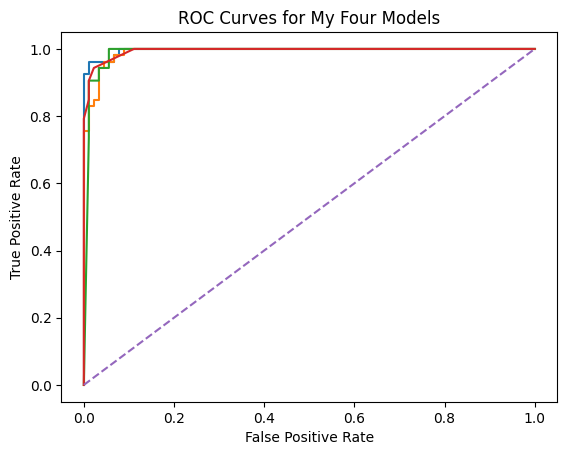

In [45]:

# I am importing the functions for ROC curves and AUC.
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


# I am defining Logistic Regression through doing standarization.
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000)
)

# I am fitting Logistic Regression to my training data.
logistic.fit(X_train, y_train)

# I am defining KNN
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# I am fitting KNN to my training data.
knn.fit(X_train, y_train)

# I am getting the predicted probabilities for each model.
prob_m = logistic.predict_proba(X_test)[:, 1]

prob_lda = lda.predict_proba(X_test)[:, 1]

prob_qda = qda.predict_proba(X_test)[:, 1]

prob_knn = knn.predict_proba(X_test)[:, 1]

# Logistic Regression
# I am calculating the ROC-AUC score.
auc_logistic = roc_auc_score(y_test_binary,
                             prob_m)

print("Logistic Regression ROC-AUC:", auc_logistic)

# I am calculating and plotting the ROC curve.
fpr, tpr, thresholds = roc_curve(y_test_binary,
                                 prob_m)
plt.plot(fpr, tpr,
         label="Logistic Regression")

# LDA
# I am calculating the ROC-AUC score.
auc_lda = roc_auc_score(y_test_binary, prob_lda)
print("LDA ROC-AUC:", auc_lda)

# I am calculating and plotting the ROC curve.
fpr, tpr, thresholds = roc_curve(y_test_binary, prob_lda)
plt.plot(fpr,
         tpr,
         label="LDA")

# QDA
# I am calculating the ROC-AUC score.
auc_qda = roc_auc_score(
          y_test_binary,
          prob_qda)

print("QDA ROC-AUC:", auc_qda)

# I am calculating and plotting the ROC curve.
fpr, tpr, thresholds = roc_curve(
        y_test_binary,
        prob_qda
    )

plt.plot(fpr, tpr,
         label="QDA")


# I am calculating the ROC-AUC score.
auc_knn = roc_auc_score(
    y_test_binary,
    prob_knn
)

print("KNN ROC-AUC:", auc_knn)

# I am calculating and plotting the ROC curve.
fpr, tpr, thresholds = roc_curve(
              y_test_binary,
              prob_knn
        )

plt.plot(fpr,
         tpr,
         label="KNN")

# I am adding a diagonal line for random guessing.
plt.plot([0, 1], [0, 1], linestyle="--")

# I am labeling the graph and displaying all four ROC curves.
plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curves for My Four Models")


plt.show()

Analysis:

All four models performed well, but overall when looking at the ROC Curve Logistic Regression performed the best since it had the highest at 0.997 which shows the difference from benign to malignant tumors. As an aspiring data scientist I want the data I am doing to improve overall patient care.

Part 7 Final Analysis

1. Compare the performance of your four classifiers. What are the most important differences ?

I think all 4 models did well but Logistic Regression had the the highest accuracy. Logistic Regression performed best and had the highest accuracy at about 97.2% and an 99.69% ROC-AUC. LDA had an accuracy at 93.0% but a 99.18% ROC-AUC. QDA had a 94.4% accuracy and a 98.96% ROC-AUC, while KNN had a 95.8% accuracy and the lowest ROC-AUC at 99.47%.

2. Identify the model you would deploy and justify your choice.

I would select Logistic Regression for additional evaluation due to it's 97.2% accuracy and a high ROC-AUC at 99.69%. It identified 49 out of the 53 malignant tumors and missed just 4.

I believe recall is particularly important since missing a malignant tumor delays medical assesment. That is a huge deal.  

Logistic Regression excelled by achieving a high recall of 92.5% and a 98.9% specificity. Logistic Regression had the highest performance. However for the real world I don't know if it would be as accurate for a real life situation that occurs.

3. Explain one limitation of your analysis

One limitation of my analysis is that the dataset might not be an accurate representation for all patients as well as hospitals. Due to this the models may perform differently.

I would need to test the models on additional datasets before assuming there would be accuracy for other patients.

4. What additional information or data would you want before using this model in the real world?

Before using my model in a real-world setting, I would want to test it with more patient data. I would also test it on newer data to see how well it works with patients that are unknown.

In a hospital, I would want doctors to review the predictions.This would help determine whether the model could be useful in helping doctors identify the patients who could need more testing.

Part 8 Visualization

For Question 2 in the Presentation

y
B    357
M    212
Name: count, dtype: int64


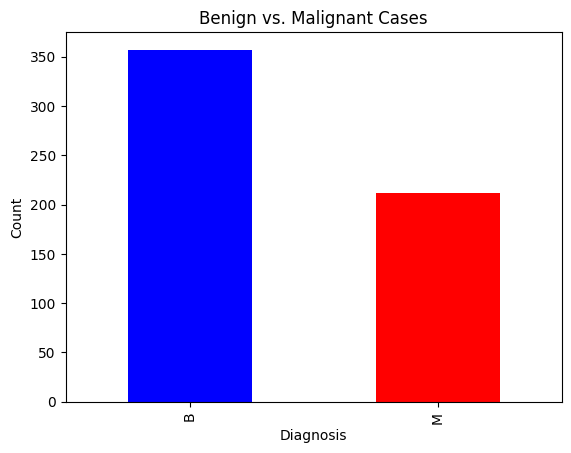

In [51]:
# Source: from textbook
# Source: College dataset
# Source: Lab 1,2

# I am counting the benign and malignant cases.
# I am counting each diagnosis.
counts = brca["y"].value_counts()

print(counts)

# I am creating a bar graph.
counts.plot(kind="bar", color=["blue", "red"])

# I am labeling the graph.
plt.xlabel("Diagnosis")

plt.ylabel("Count")

plt.title("Benign vs. Malignant Cases")

plt.show()

Conclusion

Through this project, I learned how to use data to predict whether a breast mass is benign or malignant. I explored the Breast Cancer dataset and learned a lot by working with 30 numerical features, and compared four different models to see which performed best.

I found that Logistic Regression performed the best overall, but I also learned that high accuracy does not mean a model makes every prediction correctly. Looking at recall helped me understand why missing a malignant case is important to consider.

This project showed me how data science can be used to explore real-world problems, but also why models need more testing before they can be trusted in healthcare.

Thank you for your time and effort to read this project which I have worked really hard on!

